Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
2014-04-07T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,0.0,0.0,0.0,0.0,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,WI
2014-04-08T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,null,null,null,0.0,1.0030591666666666,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,OP
2014-04-09T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,null,null,null,0.0,0.9790077083333333,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,OP
2014-04-10T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,null,null,null,0.0,0.5457591666666667,%,0.0,0.0,0.0,0.0,0.0,0.0,null,production,OP
2014-04-11T00:00:00.000Z,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,96.87589,277.27826,0.0,1.215986875,%,33.09788,10.47992,33.07195,0.0,0.0,0.0,null,production,OP


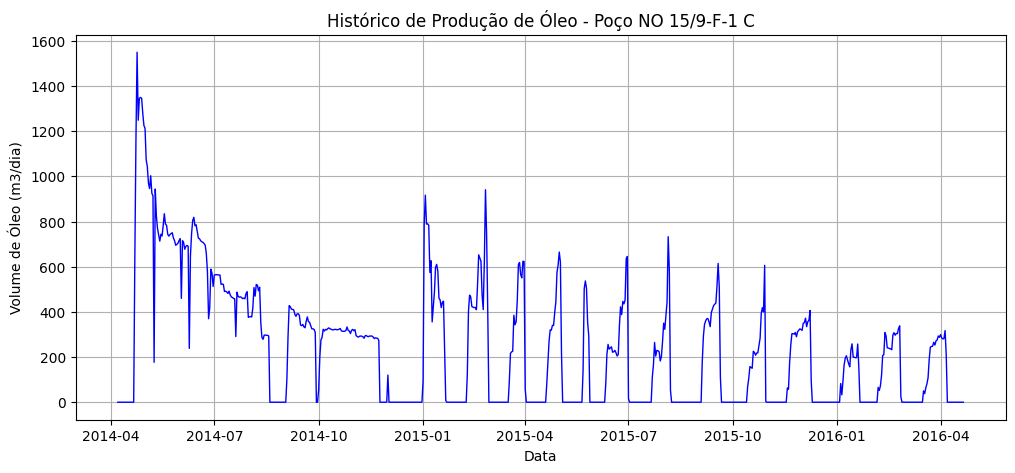

DATEPRD,DIAS_PRODUCAO,BORE_OIL_VOL
2014-04-22T00:00:00.000Z,0,631.47
2014-04-23T00:00:00.000Z,1,1166.46
2014-04-24T00:00:00.000Z,2,1549.81
2014-04-25T00:00:00.000Z,3,1248.7
2014-04-26T00:00:00.000Z,4,1345.78


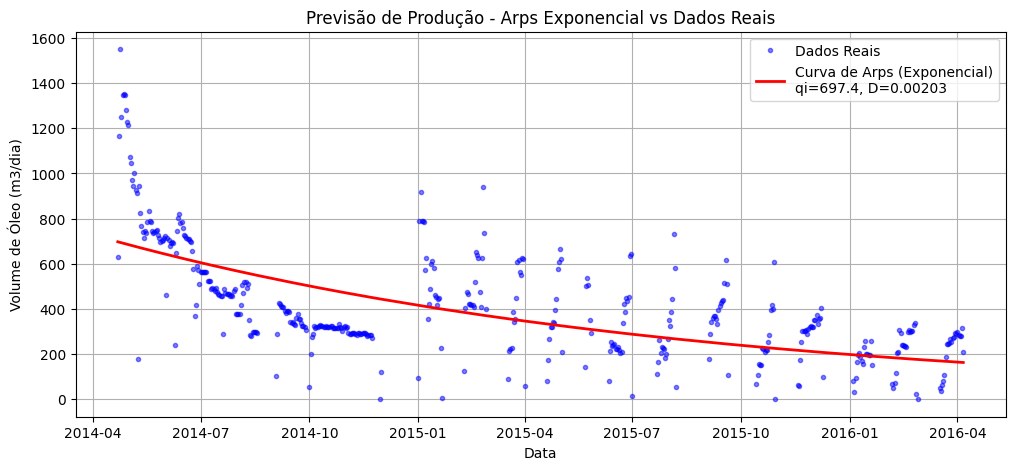

--- Estatísticas Descritivas da Produção de Óleo ---


count     746.000000
mean      238.216260
std       275.735496
min         0.000000
25%         0.000000
50%       200.685000
75%       384.605000
max      1549.810000
Name: BORE_OIL_VOL, dtype: float64

Amostras de Treino: 338 | Amostras de Teste: 85
RMSE do XGBoost no teste: 109.85 m³/dia
--- A treinar modelos para P10, P50 e P90 ---


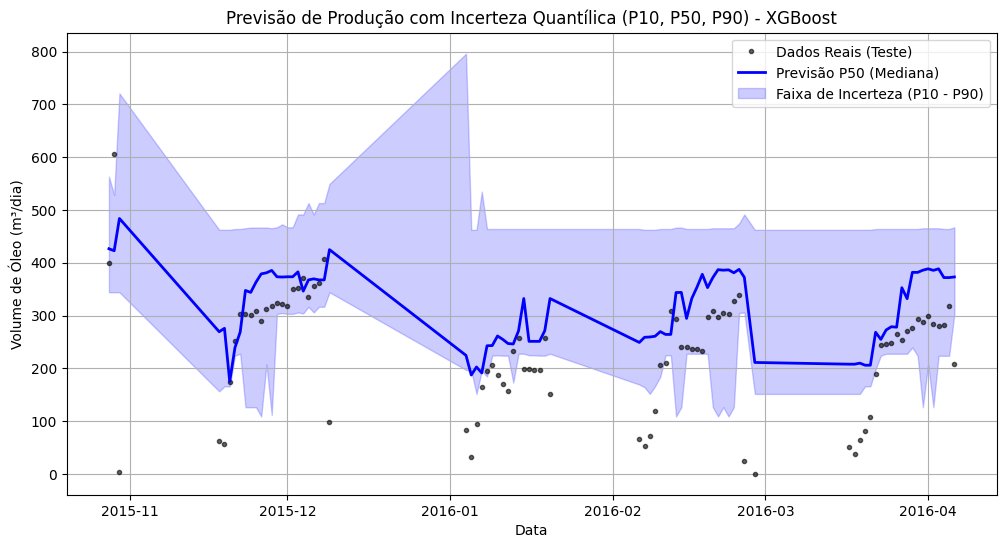

RMSE do Modelo Híbrido (Arps + Resíduo ML) no teste: 82.23 m³/dia
Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


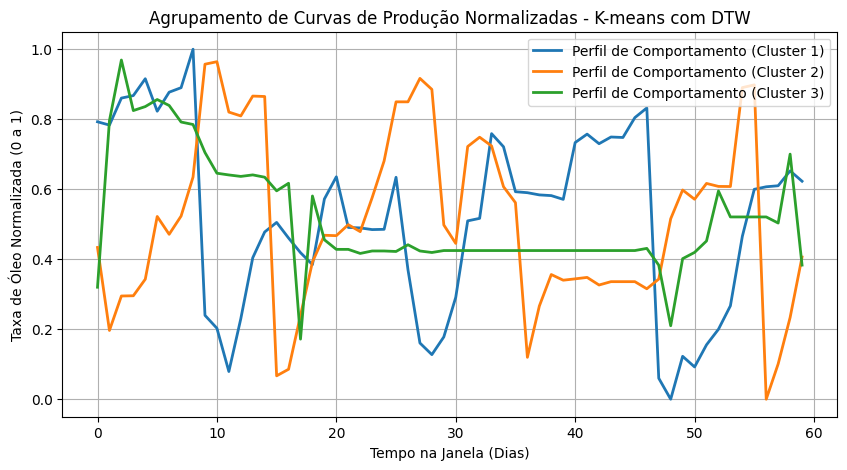

Agrupamento não supervisionado concluído! Total de janelas analisadas: 7


In [0]:
%pip install openpyxl
%pip install xgboost
import pandas as pd

# Caminho completo para o ficheiro de produção de Volve
caminho_arquivo = "/Volumes/equinor_asa_volve_data_village/public/volve/Production_data/Volve production data.xlsx"

# Lê a aba de dados diários de produção
df = pd.read_excel(caminho_arquivo, sheet_name="Daily Production Data")

# Mostra as primeiras linhas da tabela
display(df.head())
import matplotlib.pyplot as plt

# Filtrar os dados para um poço específico (ex: NO 15/9-F-1 C)
df['DATEPRD'] = pd.to_datetime(df['DATEPRD'])
df_poco = df[df['WELL_BORE_CODE'] == 'NO 15/9-F-1 C']

# Criar o gráfico da taxa de produção de óleo ao longo do tempo
plt.figure(figsize=(12, 5))
plt.plot(df_poco['DATEPRD'], df_poco['BORE_OIL_VOL'], color='blue', linewidth=1)
plt.title('Histórico de Produção de Óleo - Poço NO 15/9-F-1 C')
plt.xlabel('Data')
plt.ylabel('Volume de Óleo (m3/dia)')
plt.grid(True)
plt.show()

# 1. Filtrar apenas os dias em que houve produção efetiva de óleo (remover dias com zero ou negativos)
df_declive = df_poco[df_poco['BORE_OIL_VOL'] > 0].copy()

# 2. Criar uma coluna de tempo acumulado em dias a partir da primeira data de produção do poço
df_declive['DIAS_PRODUCAO'] = (df_declive['DATEPRD'] - df_declive['DATEPRD'].min()).dt.days

# 3. Mostrar as primeiras linhas do novo DataFrame preparado
display(df_declive[['DATEPRD', 'DIAS_PRODUCAO', 'BORE_OIL_VOL']].head())
import numpy as np
from scipy.optimize import curve_fit

# 1. Preparar os dados para o ajuste (remover eventuais NaNs)
df_Arps = df_declive.dropna(subset=['DIAS_PRODUCAO', 'BORE_OIL_VOL']).copy()
xData = df_Arps['DIAS_PRODUCAO'].values
yData = df_Arps['BORE_OIL_VOL'].values

# 2. Definir a equação do Declínio Exponencial de Arps: q(t) = qi * exp(-D * t)
def arps_exponential(t, qi, D):
    return qi * np.exp(-D * t)

# 3. Ajustar a curva aos dados reais (estimando qi inicial e taxa D)
popt, pcov = curve_fit(arps_exponential, xData, yData, p0=[yData[0], 0.001])
qi_est, D_est = popt

# 4. Gerar a curva prevista
y_pred = arps_exponential(xData, qi_est, D_est)

# 5. Visualizar o resultado (Dados reais vs Curva de Arps)
plt.figure(figsize=(12, 5))
plt.plot(df_Arps['DATEPRD'], yData, '.', color='blue', label='Dados Reais', alpha=0.5)
plt.plot(df_Arps['DATEPRD'], y_pred, color='red', linewidth=2, label=f'Curva de Arps (Exponencial)\nqi={qi_est:.1f}, D={D_est:.5f}')
plt.title('Previsão de Produção - Arps Exponencial vs Dados Reais')
plt.xlabel('Data')
plt.ylabel('Volume de Óleo (m3/dia)')
plt.legend()
plt.grid(True)
plt.show()

# Estatísticas descritivas básicas do poço de estudo
print("--- Estatísticas Descritivas da Produção de Óleo ---")
display(df_poco['BORE_OIL_VOL'].describe())

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# 1. Preparar o DataFrame base a partir dos dados limpos de declínio (Corrigido para df_declive)
df_ml = df_declive[['DATEPRD', 'DIAS_PRODUCAO', 'BORE_OIL_VOL']].copy()

# 2. Criar variáveis de desfasagem (lags) e médias móveis baseadas no histórico de produção
df_ml['OIL_LAG_1'] = df_ml['BORE_OIL_VOL'].shift(1)  # Produção do dia anterior
df_ml['OIL_LAG_7'] = df_ml['BORE_OIL_VOL'].shift(7)  # Produção de 7 dias atrás
df_ml['OIL_ROLLING_MEAN_7'] = df_ml['BORE_OIL_VOL'].rolling(window=7).mean() # Média móvel de 7 dias

# Remover valores nulos gerados pelos lags iniciais
df_ml = df_ml.dropna().reset_index(drop=True)

# 3. Divisão Treino e Teste (Últimos 20% para teste - caso cego temporal)
split_index = int(len(df_ml) * 0.8)
train_data = df_ml.iloc[:split_index]
test_data = df_ml.iloc[split_index:]

# Definir as features (X) e o alvo (y)
features = ['DIAS_PRODUCAO', 'OIL_LAG_1', 'OIL_LAG_7', 'OIL_ROLLING_MEAN_7']
target = 'BORE_OIL_VOL'

X_train, y_train = train_data[features], train_data[target]
X_test, y_test = test_data[features], test_data[target]

print(f"Amostras de Treino: {len(X_train)} | Amostras de Teste: {len(X_test)}")

# 4. Treinar um modelo inicial de XGBoost
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)

# 5. Fazer previsões no conjunto de teste
y_pred = xgb_model.predict(X_test)

# Avaliar o erro básico
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"RMSE do XGBoost no teste: {rmse:.2f} m³/dia") 

from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error

# --- 1. QUANTIFICAÇÃO DE INCERTEZA (P10, P50, P90) USANDO XGBOOST ---
print("--- A treinar modelos para P10, P50 e P90 ---")

# P10 (Quantil 0.1 - Cenário Pessimista)
model_p10 = XGBRegressor(objective='reg:quantileerror', quantile_alpha=0.1, n_estimators=100, learning_rate=0.05, random_state=42)
model_p10.fit(X_train, y_train)

# P50 (Quantil 0.5 - Cenário Mediano / Base)
model_p50 = XGBRegressor(objective='reg:quantileerror', quantile_alpha=0.5, n_estimators=100, learning_rate=0.05, random_state=42)
model_p50.fit(X_train, y_train)

# P90 (Quantil 0.9 - Cenário Otimista)
model_p90 = XGBRegressor(objective='reg:quantileerror', quantile_alpha=0.9, n_estimators=100, learning_rate=0.05, random_state=42)
model_p90.fit(X_train, y_train)

# Previsões no conjunto de teste
pred_p10 = model_p10.predict(X_test)
pred_p50 = model_p50.predict(X_test)
pred_p90 = model_p90.predict(X_test)

# --- 2. VISUALIZAÇÃO DAS FAIXAS DE INCERTEZA ---
plt.figure(figsize=(12, 6))
plt.plot(test_data['DATEPRD'], y_test, '.', color='black', label='Dados Reais (Teste)', alpha=0.6)
plt.plot(test_data['DATEPRD'], pred_p50, color='blue', linewidth=2, label='Previsão P50 (Mediana)')
plt.fill_between(test_data['DATEPRD'], pred_p10, pred_p90, color='blue', alpha=0.2, label='Faixa de Incerteza (P10 - P90)')
plt.title('Previsão de Produção com Incerteza Quantílica (P10, P50, P90) - XGBoost')
plt.xlabel('Data')
plt.ylabel('Volume de Óleo (m³/dia)')
plt.legend()
plt.grid(True)
plt.show()

# --- 3. ABORDAGEM HÍBRIDA (Resíduo de Arps + ML) ---
df_ml['ARPS_PRED'] = arps_exponential(df_ml['DIAS_PRODUCAO'], qi_est, D_est)
df_ml['RESIDUO'] = df_ml['BORE_OIL_VOL'] - df_ml['ARPS_PRED']

train_res = df_ml.iloc[:split_index]
test_res = df_ml.iloc[split_index:]

X_train_r, y_train_r = train_res[features], train_res['RESIDUO']
X_test_r, y_test_r = test_res[features], test_res['RESIDUO']

model_res = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
model_res.fit(X_train_r, y_train_r)

pred_residuo = model_res.predict(X_test_r)
pred_hibrido = test_res['ARPS_PRED'].values + pred_residuo

rmse_hibrido = np.sqrt(mean_squared_error(y_test, pred_hibrido))
print(f"RMSE do Modelo Híbrido (Arps + Resíduo ML) no teste: {rmse_hibrido:.2f} m³/dia") 

%pip install tslearn

import numpy as np
import pandas as pd
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMinMax
import matplotlib.pyplot as plt

# 1. Preparar segmentos de curvas de produção normalizadas do histórico do poço
window_size = 60  # Janelas temporais de 60 dias
series_list = []

production_vals = df_declive['BORE_OIL_VOL'].values
for i in range(0, len(production_vals) - window_size, window_size):
    segment = production_vals[i:i+window_size]
    if len(segment) == window_size and not np.isnan(segment).any():
        series_list.append(segment)

if len(series_list) > 3:
    X_ts = np.array(series_list)
    
    # Normalizar as séries temporais (MinMax)
    scaler = TimeSeriesScalerMinMax(value_range=(0, 1))
    X_ts_scaled = scaler.fit_transform(X_ts)

    # 2. Aplicar K-means com métrica DTW (Dynamic Time Warping)
    # Vamos agrupar em 3 perfis de comportamento (ex: declínio acentuado, estável, baixa produção)
    dtw_kmeans = TimeSeriesKMeans(n_clusters=3, metric="dtw", max_iter=10, random_state=42)
    labels = dtw_kmeans.fit_predict(X_ts_scaled)

    # 3. Visualizar os centroides obtidos por DTW
    plt.figure(figsize=(10, 5))
    for i, cent in enumerate(dtw_kmeans.cluster_centers_):
        plt.plot(cent.ravel(), label=f"Perfil de Comportamento (Cluster {i+1})", linewidth=2)
    
    plt.title("Agrupamento de Curvas de Produção Normalizadas - K-means com DTW")
    plt.xlabel("Tempo na Janela (Dias)")
    plt.ylabel("Taxa de Óleo Normalizada (0 a 1)")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    print(f"Agrupamento não supervisionado concluído! Total de janelas analisadas: {len(X_ts)}")
else:
    print("Ajuste o tamanho da janela para a quantidade de dados.")